# Autonomous Taxi Navigation via Q-Learning

## Overview
This notebook implements tabular **Q-Learning**, a model-free, off-policy Reinforcement Learning algorithm, to solve the **Taxi-v4** environment from Farama Foundation's Gymnasium.

### Environment Specification (`Taxi-v4`)
- **State Space**: 500 discrete states (25 taxi positions × 5 passenger locations × 4 destinations).
- **Action Space**: 6 discrete actions:
  - `0`: Move South (`down`)
  - `1`: Move North (`up`)
  - `2`: Move East (`right`)
  - `3`: Move West (`left`)
  - `4`: Pick up passenger (`pickup`)
  - `5`: Drop off passenger (`dropoff`)
- **Reward Structure**:
  - `-1` per step default penalty (encourages fast navigation).
  - `+20` for successful passenger dropoff.
  - `-10` penalty for illegal pickup or dropoff attempts.


In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
import time
from IPython.display import clear_output

# Initialize Taxi-v4 environment with text rendering mode
env = gym.make("Taxi-v4", render_mode="ansi")

print("State Space:", env.observation_space)
print("Action Space:", env.action_space)


State Space: Discrete(500)
Action Space: Discrete(6)


## 1. Environment State Inspection & Transition Dynamics

In [2]:
# Reset environment and inspect arbitrary state 328
state, info = env.reset(seed=42)
env.unwrapped.s = 328

print("Rendered State (State ID 328):")
print(env.render())

print("\nTransition dynamics P[328] for action 2 (East):")
print(env.unwrapped.P[328][2])  # (probability, next_state, reward, terminated)


Rendered State (State ID 328):
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+



Transition dynamics P[328] for action 2 (East):
[(1.0, 348, -1, False)]


## 2. Baseline: Random Action Agent (Un-trained Policy)

Before applying Q-learning, we evaluate a baseline agent taking uniformly random actions to measure performance metrics.


In [3]:
state, info = env.reset(seed=42)
epochs = 0
penalties, reward = 0, 0
frames = []
done = False

while not done:
    action = env.action_space.sample()
    state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated

    if reward == -10:
        penalties += 1
    
    frames.append({
        'frame': env.render(),
        'state': state,
        'action': action,
        'reward': reward
    })
    epochs += 1

print(f"Random Agent Performance:")
print(f"Total Timesteps Taken: {epochs}")
print(f"Total Penalties Incurred: {penalties}")


Random Agent Performance:
Total Timesteps Taken: 200
Total Penalties Incurred: 52


## 3. Q-Learning Agent Implementation

Q-Learning updates state-action values $Q(s, a)$ according to the Bellman optimality equation:

$$Q(s, a) \leftarrow (1 - \alpha) Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') \right]$$

where:
- $\alpha = 0.1$ (Learning Rate)
- $\gamma = 0.6$ (Discount Factor)
- $\epsilon = 0.1$ ($\epsilon$-Greedy Exploration Rate)


In [4]:
# Initialize Q-Table with zeros
q_table = np.zeros([env.observation_space.n, env.action_space.n])
print("Q-Table Dimensions:", q_table.shape)


Q-Table Dimensions: (500, 6)


In [5]:
# Hyperparameters
alpha = 0.1
gamma = 0.6
epsilon = 0.1
num_episodes = 50000

# Training progress metrics
all_epochs = []
all_penalties = []

print("Starting Q-Learning Training...")
start_time = time.time()

for i in range(1, num_episodes + 1):
    state, info = env.reset()
    epochs, penalties, reward = 0, 0, 0
    done = False
    
    while not done:
        # Epsilon-greedy action selection
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()  # Explore
        else:
            action = np.argmax(q_table[state])  # Exploit

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        
        # Temporal Difference (TD) update
        old_value = q_table[state, action]
        next_max = np.max(q_table[next_state])
        
        new_value = (1 - alpha) * old_value + alpha * (reward + gamma * next_max)
        q_table[state, action] = new_value

        if reward == -10:
            penalties += 1

        state = next_state
        epochs += 1
        
    all_epochs.append(epochs)
    all_penalties.append(penalties)
        
    if i % 10000 == 0:
        print(f"Episode {i}/{num_episodes} completed.")

training_time = time.time() - start_time
print(f"Training finished in {training_time:.2f} seconds.")


Starting Q-Learning Training...


Episode 10000/50000 completed.


Episode 20000/50000 completed.


Episode 30000/50000 completed.


Episode 40000/50000 completed.


Episode 50000/50000 completed.
Training finished in 17.00 seconds.


## 4. Training Convergence & Performance Plots

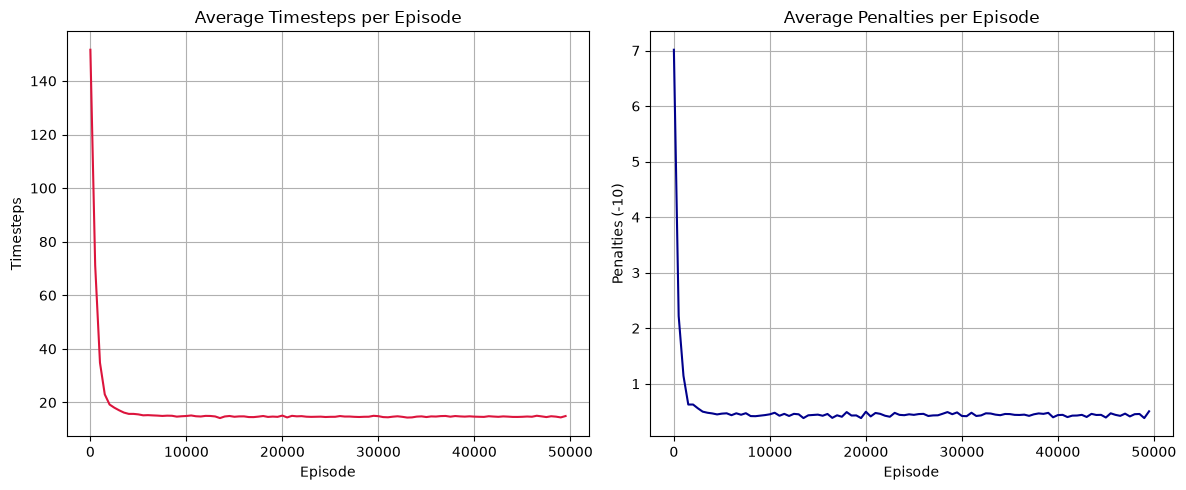

In [6]:
# Plot smoothed training curves over episode blocks
window = 500
smoothed_epochs = [np.mean(all_epochs[i:i+window]) for i in range(0, len(all_epochs), window)]
smoothed_penalties = [np.mean(all_penalties[i:i+window]) for i in range(0, len(all_penalties), window)]
x_axis = np.arange(0, len(all_epochs), window)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(x_axis, smoothed_epochs, color='crimson')
plt.title("Average Timesteps per Episode")
plt.xlabel("Episode")
plt.ylabel("Timesteps")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x_axis, smoothed_penalties, color='darkblue')
plt.title("Average Penalties per Episode")
plt.xlabel("Episode")
plt.ylabel("Penalties (-10)")
plt.grid(True)

plt.tight_layout()
plt.savefig("training_convergence.png", dpi=300)
plt.show()


## 5. Trained Q-Agent Evaluation

Evaluating the policy after convergence over 100 test episodes without exploration ($\epsilon = 0$).


In [7]:
total_epochs, total_penalties = 0, 0
eval_episodes = 100
eval_frames = []

for ep in range(eval_episodes):
    state, info = env.reset()
    epochs, penalties, reward = 0, 0, 0
    done = False
    
    while not done:
        action = np.argmax(q_table[state])
        state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        if reward == -10:
            penalties += 1
        
        if ep == 0:
            eval_frames.append({
                'frame': env.render(),
                'episode': ep + 1,
                'state': state,
                'action': action,
                'reward': reward
            })
        epochs += 1

    total_penalties += penalties
    total_epochs += epochs

print(f"--- Evaluation Results ({eval_episodes} Episodes) ---")
print(f"Average Timesteps per Episode: {total_epochs / eval_episodes:.2f}")
print(f"Average Penalties per Episode: {total_penalties / eval_episodes:.2f}")


--- Evaluation Results (100 Episodes) ---
Average Timesteps per Episode: 12.99
Average Penalties per Episode: 0.00


## 6. Sample Evaluation Trajectory Visualization

In [8]:
# Display first 5 steps of the evaluation episode
for i, f in enumerate(eval_frames[:5]):
    print(f"--- Step {i+1} ---")
    print(f["frame"])
    print(f"State: {f['state']} | Action Taken: {f['action']} | Step Reward: {f['reward']}\n")


--- Step 1 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

State: 387 | Action Taken: 2 | Step Reward: -1

--- Step 2 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

State: 287 | Action Taken: 1 | Step Reward: -1

--- Step 3 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

State: 187 | Action Taken: 1 | Step Reward: -1

--- Step 4 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

State: 87 | Action Taken: 1 | Step Reward: -1

--- Step 5 ---
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)

State: 99 | Action Taken: 4 | Step Reward: -1

